# Actividad 4. Selección de modelos preentrenados de Hugging Face

**Materia:** Gestión de proyectos de inteligencia artificial<br>
**Estudiante:** T07175241 - Gabriel Alejandro García Ángeles<br>
**Caso de uso:** clasificación de la intención de los mensajes de clientes para el chatbot de estatus de órdenes y fecha de entrega de Componentes Automotrices del Bajío (CAB)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gagarang25/Actividad4/blob/main/notebooks/Actividad4_Seleccion_Modelos_HF.ipynb)

El chatbot de CAB, definido en la Fase 1 del proyecto, primero tiene que **entender qué pide el cliente** para saber qué hacer: consultar el estatus en SAP, estimar la fecha de entrega o pasar la conversación a un ejecutivo. En este cuaderno se comparan tres modelos preentrenados de Hugging Face para esa tarea, que consiste en clasificar cada mensaje en una de cinco intenciones:

| Intención | Qué pide el cliente | Qué haría el chatbot |
|---|---|---|
| `estatus_orden` | Saber cómo va su orden | Consultar el estatus en SAP y con el transportista |
| `fecha_entrega` | Saber cuándo llega su pedido | Consultar el modelo de ETA |
| `queja` | Presentar una queja | Pasar la conversación a un ejecutivo |
| `contactar_ejecutivo` | Hablar con una persona | Pasar la conversación a un ejecutivo |
| `otro` | Cualquier otro tema (facturas, pagos, cancelaciones) | Avisar que está fuera de su alcance y canalizar |

Primero se evalúan los tres modelos tal como están publicados y después se ajustan (*fine-tuning*) con mensajes de ejemplo, para elegir el más adecuado según su precisión, su velocidad y los recursos que necesita.

**Contenido**

1. Configuración de GPU
2. Instalación de dependencias
3. Autenticación en Hugging Face Hub
4. Carga del dataset desde Hugging Face Hub
5. Codificación de etiquetas y división 80 % / 10 % / 10 %
6. Selección de los tres modelos
7. Pipeline de inferencia, métricas y latencia (línea base en validación)
8. Tabla de resultados de la línea base
9. Análisis por clase y matrices de confusión
10. Decisión automática sobre fine-tuning
11. Fine-tuning de los modelos
12. Comparación antes y después del ajuste: precisión frente a eficiencia
13. Selección del modelo y evaluación final en el conjunto de prueba
14. Conclusiones

```
              DATASET (muestra balanceada)
                        │
              División estratificada
        ┌───────────────┼───────────────┐
      TRAIN            VAL             TEST
       80 %            10 %            10 %
        │               │               │
        │     Línea base: 3 modelos     │
        │          sin ajuste           │
        │               │               │
        └─► Fine-tuning de los 3 ──►    │
                        │               │
              Selección del modelo      │
                        │               ▼
                        └────►   Prueba final:
                             sin ajuste vs. ajustado
```

> **Antes de ejecutar:** en el menú *Entorno de ejecución → Cambiar tipo de entorno de ejecución* selecciona **GPU T4**, guarda tu token de Hugging Face en *Secrets* con el nombre `HF_TOKEN` y después usa *Entorno de ejecución → Ejecutar todas*. La ejecución completa tarda alrededor de 15 minutos.

## 1. Configuración de GPU

Una GPU (unidad de procesamiento gráfico) hace muchas operaciones matemáticas al mismo tiempo, por eso los modelos de lenguaje responden y se entrenan más rápido que en un procesador normal (CPU). Esta celda comprueba que Colab asignó una GPU.

In [1]:
import torch

# nvidia-smi muestra el modelo de la GPU y la memoria disponible.
!nvidia-smi

# device=0 indica "usar la primera GPU"; device=-1 indica "usar CPU".
DISPOSITIVO = 0 if torch.cuda.is_available() else -1
NOMBRE_GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Sin GPU (CPU)"

print("\n¿GPU disponible?:", torch.cuda.is_available())
print("Dispositivo:", NOMBRE_GPU)

Sun Oct 11 05:39:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Instalación de dependencias

Se instalan las librerías del ecosistema de Hugging Face que usa el cuaderno:

- `transformers`: modelos preentrenados, *pipelines* y la clase `Trainer` para el ajuste.
- `datasets`: carga y manejo de conjuntos de datos del Hub.
- `evaluate`: métricas estandarizadas.
- `accelerate`: uso eficiente de la GPU durante el entrenamiento.
- `huggingface_hub`: conexión con el Hub (autenticación y consulta de fichas de modelos).
- `sentencepiece`: tokenizador que necesitan los modelos multilingües.

Colab ya trae varias de ellas; se instalan sin forzar una actualización para no tener que reiniciar la sesión. Al final se imprimen las versiones usadas, que son las que se registran en `requirements.txt`.

In [2]:
!pip install -q transformers datasets evaluate accelerate huggingface_hub sentencepiece scikit-learn pandas matplotlib

import platform
from importlib.metadata import version

LIBRERIAS = ["torch", "transformers", "datasets", "evaluate", "accelerate", "huggingface_hub",
             "sentencepiece", "scikit-learn", "pandas", "numpy", "matplotlib"]
VERSIONES = {"python": platform.python_version()}
VERSIONES.update({libreria: version(libreria) for libreria in LIBRERIAS})

for libreria, numero in VERSIONES.items():
    print(f"{libreria:16s} {numero}")

python           3.13.15
torch            2.11.0+cu130
transformers     5.18.0
datasets         4.8.5
evaluate         0.4.6
accelerate       1.15.0
huggingface_hub  1.33.0
sentencepiece    0.2.2
scikit-learn     1.6.1
pandas           2.2.3
numpy            2.1.3
matplotlib       3.10.0


## 3. Autenticación en Hugging Face Hub

El token es una clave personal que identifica al usuario ante el Hub. Sirve para descargar modelos y datasets con límites más altos, y es obligatorio para recursos privados o para publicar modelos.

Por seguridad **el token no se escribe en el código**. Se guarda en *Secrets* de Colab (ícono de llave 🔑 en el panel izquierdo) con el nombre `HF_TOKEN` y se activa el acceso para este cuaderno. La celda lo lee de ahí e inicia sesión.

In [3]:
import os
from huggingface_hub import login, whoami

token = os.environ.get("HF_TOKEN")
if not token:
    try:
        from google.colab import userdata      # Secrets de Colab
        token = userdata.get("HF_TOKEN")
    except Exception as error:
        print("No se pudo leer HF_TOKEN de Secrets:", type(error).__name__)

if token:
    login(token=token)
    print("Sesión iniciada en Hugging Face Hub como:", whoami()["name"])
else:
    print("Sin token: se continúa en modo anónimo (los modelos y el dataset son públicos).")

Sesión iniciada en Hugging Face Hub como: gagarang


## 4. Carga del dataset desde Hugging Face Hub

CAB es una empresa ficticia, así que no existen conversaciones reales de sus clientes. Para el prototipo se usa un dataset público del componente **Datasets** del Hub: [`bitext/Bitext-customer-support-llm-chatbot-training-dataset`](https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset), con 26,872 mensajes de clientes a un área de servicio, etiquetados con 27 intenciones (rastrear una orden, preguntar el plazo de entrega, presentar una queja, etc.). Su licencia es CDLA-Sharing-1.0.

**Los mensajes están en inglés.** El chatbot de CAB debe atender en español y en inglés, como quedó definido en la Fase 1; en esta actividad se cubre el inglés y el español queda como trabajo de la siguiente fase.

El script `src/preparar_dataset.py` prepara una **muestra balanceada**:

1. Carga el dataset con `load_dataset` de la librería `datasets`.
2. Agrupa las 27 intenciones originales en las 5 que necesita el chatbot.
3. Elimina mensajes repetidos.
4. Elige 400 mensajes por clase con una semilla fija (42), de modo que la muestra siempre sea la misma.

La siguiente celda escribe ese mismo script en el entorno de Colab para que el cuaderno no dependa de subir archivos a mano, y la que sigue lo ejecuta.

In [4]:
import os, shutil

# Se borran los resultados de ejecuciones anteriores para empezar desde cero.
for carpeta in ["results", "entrenamiento", "modelos_ajustados"]:
    shutil.rmtree(carpeta, ignore_errors=True)
for carpeta in ["src", "data", "results"]:
    os.makedirs(carpeta, exist_ok=True)

In [5]:
%%writefile src/preparar_dataset.py
"""
preparar_dataset.py
-------------------
Descarga de Hugging Face Hub el dataset público de mensajes de soporte al
cliente de Bitext y prepara la muestra balanceada que se usa para comparar
y ajustar los modelos del chatbot de CAB.

Fuente: Bitext. (s.f.). Bitext customer support LLM chatbot training dataset
        [Conjunto de datos]. Hugging Face.
        https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset
Licencia del dataset original: CDLA-Sharing-1.0.

Pasos:
  1. Carga el dataset con la librería datasets de Hugging Face.
  2. Agrupa las 27 intenciones originales en las 5 que necesita el chatbot:
       estatus_orden        <- track_order
       fecha_entrega        <- delivery_period
       queja                <- complaint
       contactar_ejecutivo  <- contact_human_agent, contact_customer_service
       otro                 <- el resto (facturas, pagos, cancelaciones, cuentas...)
  3. Elimina mensajes repetidos.
  4. Toma una muestra balanceada (mismo número de mensajes por clase) con semilla fija.

Uso:
    python src/preparar_dataset.py
Salida:
    data/mensajes_clientes_muestra.csv
"""

import hashlib
import os

import pandas as pd
from datasets import load_dataset

DATASET_HF = "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
RUTA_SALIDA = os.path.join("data", "mensajes_clientes_muestra.csv")
SEMILLA = 42
MENSAJES_POR_CLASE = 400

# Intenciones del chatbot de CAB y las intenciones originales que agrupa cada una.
INTENCIONES_CAB = {
    "estatus_orden": ["track_order"],
    "fecha_entrega": ["delivery_period"],
    "queja": ["complaint"],
    "contactar_ejecutivo": ["contact_human_agent", "contact_customer_service"],
}


def asignar_intencion(intent_original):
    """Convierte la intención original del dataset en una de las 5 clases del chatbot."""
    for clase, originales in INTENCIONES_CAB.items():
        if intent_original in originales:
            return clase
    return "otro"


def preparar(tabla):
    """Limpia el dataset original y regresa la muestra balanceada."""
    faltantes = [i for lista in INTENCIONES_CAB.values() for i in lista
                 if i not in set(tabla["intent"])]
    if faltantes:
        raise ValueError(f"El dataset no contiene las intenciones esperadas: {faltantes}")

    tabla = tabla.dropna(subset=["instruction", "intent"]).copy()
    tabla["mensaje"] = (tabla["instruction"].astype(str)
                        .str.replace(r"\s+", " ", regex=True).str.strip())
    tabla = tabla[tabla["mensaje"].str.len() > 0]
    tabla = tabla.drop_duplicates(subset="mensaje")
    tabla["intencion"] = tabla["intent"].apply(asignar_intencion)
    tabla["num_palabras"] = tabla["mensaje"].str.split().str.len()
    # Se ordena antes de muestrear para que el resultado no dependa del orden del archivo.
    tabla = tabla.sort_values(["intencion", "mensaje"]).reset_index(drop=True)
    disponibles = tabla["intencion"].value_counts()
    print("Mensajes disponibles por clase después de la limpieza:")
    print(disponibles.to_string())

    por_clase = min(MENSAJES_POR_CLASE, int(disponibles.min()))
    muestra = pd.concat([
        grupo.sample(n=por_clase, random_state=SEMILLA)
        for _, grupo in tabla.groupby("intencion", sort=True)
    ])
    muestra = muestra.sample(frac=1, random_state=SEMILLA).reset_index(drop=True)
    muestra.insert(0, "id", range(1, len(muestra) + 1))
    muestra = muestra.rename(columns={"intent": "intencion_original", "category": "categoria_original"})
    return muestra[["id", "mensaje", "intencion", "intencion_original", "categoria_original", "num_palabras"]]


def main():
    original = load_dataset(DATASET_HF, split="train").to_pandas()
    print(f"Dataset descargado de Hugging Face Hub: {DATASET_HF}")
    print(f"Mensajes en el dataset original: {len(original)}")
    print(f"Columnas originales: {list(original.columns)}")
    print(f"Intenciones originales: {original['intent'].nunique()}")
    muestra = preparar(original)
    os.makedirs(os.path.dirname(RUTA_SALIDA), exist_ok=True)
    muestra.to_csv(RUTA_SALIDA, index=False, encoding="utf-8", lineterminator="\n")
    with open(RUTA_SALIDA, "rb") as f:
        huella = hashlib.md5(f.read()).hexdigest()
    print(f"\nMuestra guardada: {RUTA_SALIDA} ({len(muestra)} mensajes, "
          f"{len(muestra) // muestra['intencion'].nunique()} por clase)")
    print(f"Huella MD5 del archivo: {huella}")


if __name__ == "__main__":
    main()

Overwriting src/preparar_dataset.py


In [6]:
!python src/preparar_dataset.py

Dataset descargado de Hugging Face Hub: bitext/Bitext-customer-support-llm-chatbot-training-dataset
Mensajes en el dataset original: 26872
Columnas originales: ['flags', 'instruction', 'category', 'intent', 'response']
Intenciones originales: 27
Mensajes disponibles por clase después de la limpieza:
intencion
otro                   19765
contactar_ejecutivo     1993
queja                    998
fecha_entrega            997
estatus_orden            801

Muestra guardada: data/mensajes_clientes_muestra.csv (2000 mensajes, 400 por clase)
Huella MD5 del archivo: b3fedfd804cd1e031640b294855c6f66


La muestra se vuelve a cargar con la librería `datasets` y se convierte a una tabla de `pandas` para revisarla. Campos del dataset:

| Campo | Descripción |
|---|---|
| `id` | Número consecutivo del mensaje en la muestra |
| `mensaje` | Texto del mensaje del cliente (en inglés) |
| `intencion` | Etiqueta real: una de las 5 intenciones del chatbot |
| `intencion_original` | Intención que tenía el mensaje en el dataset de Bitext |
| `categoria_original` | Categoría que tenía el mensaje en el dataset de Bitext |
| `num_palabras` | Número de palabras del mensaje |

In [7]:
import pandas as pd
from datasets import load_dataset

RUTA_DATASET = "data/mensajes_clientes_muestra.csv"

dataset = load_dataset("csv", data_files=RUTA_DATASET, split="train")
df = dataset.to_pandas()

print(dataset)
print("\nDistribución de clases:")
print(df["intencion"].value_counts())
print("\nPromedio de palabras por mensaje:", round(df["num_palabras"].mean(), 1))
print("Intenciones originales agrupadas en 'otro':", df[df["intencion"] == "otro"]["intencion_original"].nunique())

pd.set_option("display.max_colwidth", 110)
display(df.groupby("intencion").head(1)[["mensaje", "intencion", "intencion_original"]])

Dataset({
    features: ['id', 'mensaje', 'intencion', 'intencion_original', 'categoria_original', 'num_palabras'],
    num_rows: 2000
})

Distribución de clases:
intencion
queja                  400
contactar_ejecutivo    400
otro                   400
fecha_entrega          400
estatus_orden          400
Name: count, dtype: int64

Promedio de palabras por mensaje: 9.4
Intenciones originales agrupadas en 'otro': 22


,mensaje,intencion,intencion_original
0,i want assistance filing a complaint against ur business,queja,complaint
1,I need help to check what hours I can call customer support,contactar_ejecutivo,contact_customer_service
2,i do not know what i have to do to get invoice #37777,otro,get_invoice
3,where do i check how long it takes for my shipment to arrive,fecha_entrega,delivery_period
13,wanna see orer {{Order Number}} current status can ya help me,estatus_orden,track_order


**Conclusión parcial.** La muestra tiene 2,000 mensajes, 400 por cada intención, con 9.4 palabras en promedio (entre 2 y 16). La clase `otro` reúne 22 intenciones originales distintas (facturas, pagos, reembolsos, cuentas, cancelaciones) y `contactar_ejecutivo` combina dos (203 y 197 mensajes). Los mensajes incluyen errores de escritura y marcadores como `{{Order Number}}` en lugar de datos reales, lo que se parece a cómo escribe un cliente y evita manejar datos personales. Al estar balanceada, el *accuracy* es una medida confiable y el promedio ponderado coincide con el promedio macro.

## 5. Codificación de etiquetas y división 80 % / 10 % / 10 %

Los modelos trabajan con números, no con palabras, así que cada intención se convierte en un número del 0 al 4.

Después el dataset se divide en tres partes, como se vio en clase:

- **Entrenamiento (80 %):** con estos mensajes se ajustan los modelos.
- **Validación (10 %):** sirve para comparar los modelos y vigilar el ajuste en cada época.
- **Prueba (10 %):** se reserva y se usa una sola vez, al final, para medir el resultado con mensajes que el modelo nunca vio.

La división es estratificada: mantiene la misma proporción de clases en las tres partes.

In [8]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
CLASES = ["estatus_orden", "fecha_entrega", "queja", "contactar_ejecutivo", "otro"]
label2id = {clase: numero for numero, clase in enumerate(CLASES)}
id2label = {numero: clase for clase, numero in label2id.items()}
print("Codificación de etiquetas:", label2id)

df["labels"] = df["intencion"].map(label2id).astype(int)

# Primer corte: 80 % entrenamiento y 20 % temporal.
df_train, df_temp = train_test_split(
    df, test_size=0.20, random_state=RANDOM_STATE, stratify=df["labels"]
)
# Segundo corte: el 20 % temporal se parte a la mitad (10 % validación, 10 % prueba).
df_val, df_test = train_test_split(
    df_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=df_temp["labels"]
)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

total = len(df)
print("\n" + "=" * 60)
print("DIVISIÓN DEL DATASET")
print("=" * 60)
for nombre, parte in [("Train", df_train), ("Validation", df_val), ("Test", df_test)]:
    por_clase_parte = parte["intencion"].value_counts().reindex(CLASES).tolist()
    print(f"{nombre:11s} {len(parte):5d} ({len(parte) / total:.1%})  mensajes por clase: {por_clase_parte}")
print("-" * 60)
print(f"{'TOTAL':11s} {total:5d}")

textos_val = df_val["mensaje"].tolist()
reales_val = df_val["intencion"].tolist()
textos_test = df_test["mensaje"].tolist()
reales_test = df_test["intencion"].tolist()

Codificación de etiquetas: {'estatus_orden': 0, 'fecha_entrega': 1, 'queja': 2, 'contactar_ejecutivo': 3, 'otro': 4}

DIVISIÓN DEL DATASET
Train        1600 (80.0%)  mensajes por clase: [320, 320, 320, 320, 320]
Validation    200 (10.0%)  mensajes por clase: [40, 40, 40, 40, 40]
Test          200 (10.0%)  mensajes por clase: [40, 40, 40, 40, 40]
------------------------------------------------------------
TOTAL        2000


## 6. Selección de los tres modelos

Ningún modelo del Hub viene entrenado con las cinco intenciones de CAB. Por eso se buscaron, en la sección **Models**, modelos de **clasificación zero-shot**: modelos que pueden clasificar un texto en categorías que nunca vieron, a partir de una descripción de cada categoría. Permiten probar el caso de uso desde el primer momento, sin entrenar nada. Se eligieron tres de distinto tamaño:

| Modelo | Por qué se eligió |
|---|---|
| `facebook/bart-large-mnli` | El más grande y el más usado para zero-shot; solo inglés. |
| `MoritzLaurer/mDeBERTa-v3-base-mnli-xnli` | Tamaño medio y multilingüe; serviría también para los mensajes en español. |
| `MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli` | Pequeño y multilingüe; pensado para ser rápido. |

La celda consulta la ficha de cada modelo en el Hub para obtener datos que también son criterios de selección: tarea, licencia, descargas y peso del archivo.

In [9]:
from huggingface_hub import model_info

# Identificadores de los tres modelos en Hugging Face Hub.
MODELOS = {
    "BART-large (inglés)": "facebook/bart-large-mnli",
    "mDeBERTa-v3 (multilingüe)": "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    "MiniLMv2 (multilingüe)": "MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli",
}


def consultar_ficha(id_modelo):
    """Lee de Hugging Face Hub la tarea, licencia, descargas y peso de un modelo."""
    info = model_info(id_modelo, files_metadata=True)
    licencia = next((t.split(":", 1)[1] for t in (info.tags or []) if t.startswith("license:")),
                    "no declarada")
    pesos = [s.size for s in (info.siblings or [])
             if s.size and s.rfilename in ("model.safetensors", "pytorch_model.bin")]
    return {
        "id_modelo": id_modelo,
        "tarea": info.pipeline_tag,
        "licencia": licencia,
        "descargas_mes": info.downloads,
        "peso_archivo_mb": round(max(pesos) / 1024**2, 1) if pesos else None,
    }

fichas = pd.DataFrame([consultar_ficha(i) for i in MODELOS.values()])
fichas.insert(0, "modelo", list(MODELOS.keys()))
display(fichas)

,modelo,id_modelo,tarea,licencia,descargas_mes,peso_archivo_mb
0,BART-large (inglés),facebook/bart-large-mnli,zero-shot-classification,mit,2598918,1554.0
1,mDeBERTa-v3 (multilingüe),MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,zero-shot-classification,mit,121654,531.9
2,MiniLMv2 (multilingüe),MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,zero-shot-classification,mit,16565,408.2


## 7. Pipeline de inferencia, métricas y latencia (línea base en validación)

Un *pipeline* de Hugging Face junta en un solo paso el tokenizador (convierte el texto en números), el modelo y la conversión de la salida en una etiqueta. Aquí se usa el pipeline `zero-shot-classification`: se le da el mensaje y la descripción de cada intención, y el modelo responde cuál descripción encaja mejor. Los tres modelos se evalúan **tal como están publicados**, sin ajuste, sobre el conjunto de **validación**. El conjunto de prueba no se toca todavía.

Para cada modelo:

1. Se carga el modelo en la GPU.
2. Se hace una inferencia de calentamiento que no se mide (la primera siempre es más lenta).
3. Se clasifican los mensajes por lotes y se calculan las métricas.
4. Se mide la **latencia**: el tiempo que tarda en responder a un solo mensaje. Se envían 100 mensajes de uno en uno y la medición se repite 3 veces (300 mediciones). Se reporta la mediana (el valor central, que no se altera por picos aislados), el promedio y el percentil 95 (el tiempo que no se supera en 95 de cada 100 consultas).
5. Se registra el número de parámetros y la memoria de GPU utilizada.

**Métricas** (explicadas con la clase *queja* como ejemplo):

- **Accuracy:** de todos los mensajes, qué proporción se clasificó bien.
- **Precision:** de los que el modelo marcó como queja, cuántos lo eran realmente.
- **Recall:** de los que realmente eran quejas, cuántos encontró el modelo.
- **F1-score:** resume precision y recall en un solo número (su media armónica).

Se usa el promedio ponderado (cada clase pesa según su número de mensajes) y se añade el F1 macro, que da el mismo peso a todas las clases.

In [10]:
import gc, time
import numpy as np
import transformers
from transformers import pipeline
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support

transformers.logging.set_verbosity_error()   # oculta avisos que no afectan el resultado
transformers.set_seed(42)                    # semilla fija para reproducibilidad

# Descripción en inglés de cada clase. Los modelos sin ajuste eligen la frase
# que mejor describe el mensaje (clasificación zero-shot).
DESCRIPCIONES = {
    "estatus_orden": "the status or tracking of an order",
    "fecha_entrega": "how long the delivery takes or when the order will arrive",
    "queja": "making a complaint",
    "contactar_ejecutivo": "talking to a human agent or contacting customer service",
    "otro": "another topic such as invoices, payments, refunds, cancellations or accounts",
}
PLANTILLA = "This message is about {}."
FRASE_A_CLASE = {frase: clase for clase, frase in DESCRIPCIONES.items()}

TAMANO_LOTE = 16      # mensajes que se procesan juntos en la prueba por lotes
N_LATENCIA = 100      # mensajes que se envían de uno en uno para medir latencia
N_REPETICIONES = 3    # veces que se repite la medición de latencia


def calcular_metricas(reales, predichas):
    """Calcula accuracy, precision, recall y F1 (promedio ponderado) y F1 macro."""
    accuracy = accuracy_score(reales, predichas)
    precision, recall, f1, _ = precision_recall_fscore_support(
        reales, predichas, average="weighted", zero_division=0
    )
    f1_macro = f1_score(reales, predichas, average="macro", zero_division=0)
    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "f1_macro": f1_macro,
    }


def sincronizar():
    """Espera a que la GPU termine su trabajo para que el tiempo medido sea real."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def como_lista(salida):
    """Los pipelines regresan un diccionario si reciben un solo texto; aquí se unifica."""
    return salida if isinstance(salida, list) else [salida]


def predecir_zero_shot(clasificador, textos):
    """Clasifica con un modelo sin ajuste: elige la descripción con mayor puntaje."""
    salidas = como_lista(clasificador(
        textos, candidate_labels=list(DESCRIPCIONES.values()),
        hypothesis_template=PLANTILLA, batch_size=TAMANO_LOTE,
    ))
    return [(FRASE_A_CLASE[s["labels"][0]], float(s["scores"][0])) for s in salidas]


def predecir_ajustado(clasificador, textos):
    """Clasifica con un modelo ya ajustado, que responde directamente con la clase."""
    salidas = como_lista(clasificador(textos, batch_size=TAMANO_LOTE, truncation=True))
    return [(s["label"], float(s["score"])) for s in salidas]


def medir_clasificador(nombre, id_modelo, etapa, clasificador, predecir, textos, etiquetas_reales):
    """Clasifica los textos con un pipeline ya cargado y mide precisión y latencia."""
    # 1. Calentamiento: la primera inferencia siempre es más lenta y no se mide.
    predecir(clasificador, textos[:8])
    sincronizar()

    # 2. Inferencia por lotes sobre todos los textos (de aquí salen las métricas).
    inicio = time.perf_counter()
    salidas = predecir(clasificador, textos)
    sincronizar()
    tiempo_lote = time.perf_counter() - inicio

    # 3. Latencia: un mensaje a la vez, como llegaría al chatbot.
    #    Se repite varias veces porque en una GPU compartida el tiempo varía.
    tiempos_ms = []
    for _ in range(N_REPETICIONES):
        for texto in textos[:N_LATENCIA]:
            inicio = time.perf_counter()
            predecir(clasificador, texto)
            sincronizar()
            tiempos_ms.append((time.perf_counter() - inicio) * 1000)

    # 4. Métricas de clasificación.
    predichas = [clase for clase, _ in salidas]
    confianzas = [confianza for _, confianza in salidas]
    parametros = sum(p.numel() for p in clasificador.model.parameters())
    resultado = {"modelo": nombre, "id_modelo": id_modelo, "etapa": etapa}
    resultado.update(calcular_metricas(etiquetas_reales, predichas))
    resultado.update({
        "latencia_mediana_ms": float(np.median(tiempos_ms)),
        "latencia_media_ms": float(np.mean(tiempos_ms)),
        "latencia_p95_ms": float(np.percentile(tiempos_ms, 95)),
        "mensajes_por_segundo": len(textos) / tiempo_lote,
        "parametros_millones": parametros / 1e6,
        "memoria_gpu_pico_mb": (torch.cuda.max_memory_allocated() / 1024**2
                                if torch.cuda.is_available() else 0.0),
    })
    return resultado, predichas, confianzas


def evaluar_modelo(nombre, origen, etapa, textos, etiquetas_reales, dispositivo, id_modelo=None):
    """Carga un modelo, lo evalúa y libera la memoria al terminar.

    etapa = "sin ajuste": modelo del Hub usado con clasificación zero-shot.
    etapa = "con fine-tuning": modelo ajustado y guardado en una carpeta local.
    """
    hay_gpu = torch.cuda.is_available() and dispositivo != -1
    if hay_gpu:
        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    if etapa == "sin ajuste":
        clasificador = pipeline("zero-shot-classification", model=origen, device=dispositivo)
        predecir = predecir_zero_shot
    else:
        clasificador = pipeline("text-classification", model=origen, device=dispositivo)
        predecir = predecir_ajustado

    resultado, predichas, confianzas = medir_clasificador(
        nombre, id_modelo or origen, etapa, clasificador, predecir, textos, etiquetas_reales
    )

    # Se libera la memoria antes de cargar el siguiente modelo.
    del clasificador
    gc.collect()
    if hay_gpu:
        torch.cuda.empty_cache()
    return resultado, predichas, confianzas

In [11]:
resultados_base = []
pred_val = df_val[["id", "mensaje", "intencion"]].copy()

for nombre, id_modelo in MODELOS.items():
    print(f"Evaluando sin ajuste: {nombre} ({id_modelo}) ...")
    resultado, predichas, confianzas = evaluar_modelo(
        nombre, id_modelo, "sin ajuste", textos_val, reales_val, DISPOSITIVO
    )
    resultados_base.append(resultado)
    pred_val[f"base_{nombre}"] = predichas
    pred_val[f"confianza_base_{nombre}"] = np.round(confianzas, 4)
    print(f"   accuracy={resultado['accuracy']:.4f}  f1={resultado['f1']:.4f}  "
          f"latencia mediana={resultado['latencia_mediana_ms']:.1f} ms\n")

print("Evaluación de línea base terminada.")

Evaluando sin ajuste: BART-large (inglés) (facebook/bart-large-mnli) ...


   accuracy=0.5850  f1=0.4845  latencia mediana=60.5 ms

Evaluando sin ajuste: mDeBERTa-v3 (multilingüe) (MoritzLaurer/mDeBERTa-v3-base-mnli-xnli) ...


   accuracy=0.6100  f1=0.5803  latencia mediana=49.4 ms

Evaluando sin ajuste: MiniLMv2 (multilingüe) (MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli) ...


   accuracy=0.4650  f1=0.3565  latencia mediana=13.4 ms

Evaluación de línea base terminada.


Como comprobación, se recalcula el *accuracy* con la librería `evaluate` de Hugging Face. Debe coincidir con el valor obtenido con scikit-learn.

In [12]:
try:
    import evaluate
    metrica = evaluate.load("accuracy")
    for r in resultados_base:
        valor = metrica.compute(
            predictions=[label2id[p] for p in pred_val[f"base_{r['modelo']}"]],
            references=[label2id[e] for e in reales_val],
        )["accuracy"]
        print(f"{r['modelo']:28s} evaluate={valor:.4f}  scikit-learn={r['accuracy']:.4f}")
except Exception as error:
    print("No se pudo usar la librería evaluate en este entorno:", type(error).__name__, error)

BART-large (inglés)          evaluate=0.5850  scikit-learn=0.5850
mDeBERTa-v3 (multilingüe)    evaluate=0.6100  scikit-learn=0.6100
MiniLMv2 (multilingüe)       evaluate=0.4650  scikit-learn=0.4650


## 8. Tabla de resultados de la línea base

Se reúnen las métricas, la latencia y los recursos de los tres modelos sin ajuste.

In [13]:
tabla_base = pd.DataFrame(resultados_base).merge(fichas.drop(columns="modelo"), on="id_modelo")

columnas_metricas = ["modelo", "accuracy", "precision", "recall", "f1", "f1_macro"]
columnas_eficiencia = ["modelo", "latencia_mediana_ms", "latencia_media_ms", "latencia_p95_ms",
                       "mensajes_por_segundo", "parametros_millones", "peso_archivo_mb",
                       "memoria_gpu_pico_mb", "licencia"]

print(f"MÉTRICAS DE CLASIFICACIÓN SIN AJUSTE (validación, {len(df_val)} mensajes)")
display(tabla_base[columnas_metricas].round(4))
print("EFICIENCIA Y RECURSOS SIN AJUSTE")
display(tabla_base[columnas_eficiencia].round(2))

MÉTRICAS DE CLASIFICACIÓN SIN AJUSTE (validación, 200 mensajes)


,modelo,accuracy,precision,recall,f1,f1_macro
0,BART-large (inglés),0.585,0.8110,0.585,0.4845,0.4845
1,mDeBERTa-v3 (multilingüe),0.610,0.7121,0.610,0.5803,0.5803
2,MiniLMv2 (multilingüe),0.465,0.5887,0.465,0.3565,0.3565


EFICIENCIA Y RECURSOS SIN AJUSTE


,modelo,latencia_mediana_ms,latencia_media_ms,latencia_p95_ms,mensajes_por_segundo,parametros_millones,peso_archivo_mb,memoria_gpu_pico_mb,licencia
0,BART-large (inglés),60.49,73.70,131.74,21.78,407.34,1554.0,1597.18,mit
1,mDeBERTa-v3 (multilingüe),49.43,61.15,114.75,29.84,278.81,531.9,606.99,mit
2,MiniLMv2 (multilingüe),13.41,19.29,35.98,70.56,107.00,408.2,432.97,mit


## 9. Análisis por clase y matrices de confusión

La matriz de confusión muestra en qué se equivoca cada modelo: las filas son la intención real y las columnas la intención que predijo el modelo. Los aciertos quedan en la diagonal.

BART-large (inglés) — validación, sin ajuste
                     precision    recall  f1-score   support

      estatus_orden     0.3883    1.0000    0.5594        40
      fecha_entrega     1.0000    0.0250    0.0488        40
              queja     0.6667    1.0000    0.8000        40
contactar_ejecutivo     1.0000    0.8500    0.9189        40
               otro     1.0000    0.0500    0.0952        40

           accuracy                         0.5850       200
          macro avg     0.8110    0.5850    0.4845       200
       weighted avg     0.8110    0.5850    0.4845       200

mDeBERTa-v3 (multilingüe) — validación, sin ajuste
                     precision    recall  f1-score   support

      estatus_orden     0.4494    1.0000    0.6202        40
      fecha_entrega     1.0000    0.2750    0.4314        40
              queja     0.7358    0.9750    0.8387        40
contactar_ejecutivo     1.0000    0.5750    0.7302        40
               otro     0.3750    0.2250    0.

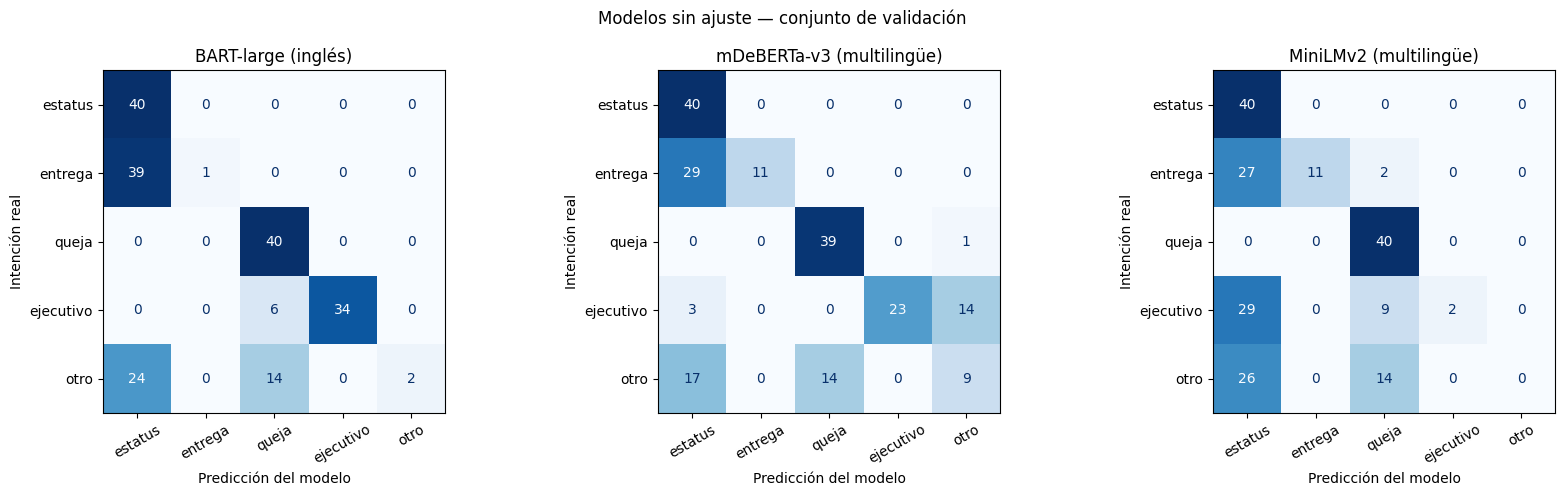

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

ETIQUETAS_CORTAS = ["estatus", "entrega", "queja", "ejecutivo", "otro"]


def metricas_por_clase(nombre, etapa, conjunto, reales, predichas):
    """Regresa precision, recall y F1 de cada clase como lista de filas."""
    reporte = classification_report(reales, predichas, labels=CLASES, output_dict=True, zero_division=0)
    return [{"modelo": nombre, "etapa": etapa, "conjunto": conjunto, "clase": clase,
             "precision": reporte[clase]["precision"], "recall": reporte[clase]["recall"],
             "f1": reporte[clase]["f1-score"], "mensajes": int(reporte[clase]["support"])}
            for clase in CLASES]


def dibujar_matrices(columnas, titulos, reales, tabla_predicciones, titulo_general, archivo):
    """Dibuja una matriz de confusión por cada columna de predicciones."""
    fig, ejes = plt.subplots(1, len(columnas), figsize=(5.6 * len(columnas), 5))
    for eje, columna, titulo in zip(np.atleast_1d(ejes), columnas, titulos):
        matriz = confusion_matrix(reales, tabla_predicciones[columna], labels=CLASES)
        ConfusionMatrixDisplay(matriz, display_labels=ETIQUETAS_CORTAS).plot(
            ax=eje, cmap="Blues", colorbar=False, values_format="d")
        eje.set_title(titulo)
        eje.set_xlabel("Predicción del modelo")
        eje.set_ylabel("Intención real")
        eje.tick_params(axis="x", rotation=30)
    plt.suptitle(titulo_general)
    plt.tight_layout()
    plt.savefig(archivo, dpi=150, bbox_inches="tight")
    plt.show()


por_clase = []
for nombre in MODELOS:
    print("=" * 66)
    print(nombre, "— validación, sin ajuste")
    print("=" * 66)
    print(classification_report(reales_val, pred_val[f"base_{nombre}"],
                                labels=CLASES, digits=4, zero_division=0))
    por_clase += metricas_por_clase(nombre, "sin ajuste", "validación", reales_val, pred_val[f"base_{nombre}"])

dibujar_matrices([f"base_{n}" for n in MODELOS], list(MODELOS), reales_val, pred_val,
                 "Modelos sin ajuste — conjunto de validación",
                 "results/matrices_confusion_base_validacion.png")

**Conclusión parcial.** Sin ajuste, ningún modelo alcanza el umbral: el mejor es mDeBERTa-v3 con *accuracy* de 0.610, seguido de BART-large con 0.585 y MiniLMv2 con 0.465. Los tres reconocen bien las quejas (*recall* de 0.975 a 1.000) y el estatus de orden (*recall* de 1.000), pero fallan en dos puntos. Primero, confunden `fecha_entrega` con `estatus_orden`: de 40 mensajes que preguntan cuándo llega el pedido, entre 27 y 39 se clasifican como estatus, porque las dos preguntas se parecen mucho. Segundo, casi no reconocen la clase `otro` (*recall* de 0.050, 0.225 y 0.000), que no se puede describir con una sola frase. Para el chatbot esto es grave: mensajes que debían pasar a un ejecutivo se responderían en automático como si fueran consultas de estatus.

## 10. Decisión automática sobre fine-tuning

Se aplican los umbrales definidos para el caso de uso:

- **F1-score ponderado ≥ 0.80** y **accuracy ≥ 0.80** (el mismo criterio visto en clase para decidir si hace falta *fine-tuning*).
- **Latencia mediana ≤ 100 ms** por mensaje con GPU, para que el cliente no perciba espera antes de que el chatbot empiece a responder.

Si algún modelo no cumple los dos umbrales, se ajusta con *fine-tuning*.

In [15]:
UMBRAL_F1 = 0.80
UMBRAL_ACCURACY = 0.80
UMBRAL_LATENCIA_MS = 100


def aplicar_umbrales(tabla):
    """Agrega a la tabla las columnas que indican si cada modelo cumple los umbrales."""
    tabla = tabla.copy()
    tabla["cumple_precision"] = (tabla["f1"] >= UMBRAL_F1) & (tabla["accuracy"] >= UMBRAL_ACCURACY)
    tabla["cumple_latencia"] = tabla["latencia_mediana_ms"] <= UMBRAL_LATENCIA_MS
    tabla["cumple_todo"] = tabla["cumple_precision"] & tabla["cumple_latencia"]
    return tabla


tabla_base = aplicar_umbrales(tabla_base)
tabla_base["requiere_fine_tuning"] = ~tabla_base["cumple_todo"]
requiere_finetuning = bool(tabla_base["requiere_fine_tuning"].any())

print("=" * 60)
print("DECISIÓN DE FINE-TUNING")
print("=" * 60)
display(tabla_base[["modelo", "accuracy", "f1", "latencia_mediana_ms",
                    "cumple_precision", "cumple_latencia", "requiere_fine_tuning"]].round(4))
print(f"¿Se requiere fine-tuning?: {requiere_finetuning}")

DECISIÓN DE FINE-TUNING


,modelo,accuracy,f1,latencia_mediana_ms,cumple_precision,cumple_latencia,requiere_fine_tuning
0,BART-large (inglés),0.585,0.4845,60.4948,False,True,True
1,mDeBERTa-v3 (multilingüe),0.610,0.5803,49.4281,False,True,True
2,MiniLMv2 (multilingüe),0.465,0.3565,13.4063,False,True,True


¿Se requiere fine-tuning?: True


## 11. Fine-tuning de los modelos

El *fine-tuning* consiste en continuar el entrenamiento de un modelo preentrenado con ejemplos propios del caso de uso, para que aprenda sus particularidades. Aquí cada modelo se ajusta con los mensajes de entrenamiento, siguiendo los pasos vistos en clase:

1. Convertir las tablas a `Dataset` de Hugging Face.
2. Tokenizar los mensajes.
3. Usar relleno dinámico (*dynamic padding*): cada lote se rellena solo hasta el largo de su mensaje más extenso.
4. Cargar el modelo para clasificación con las 5 intenciones. El modelo original termina en una capa de 3 salidas (propia de su entrenamiento anterior); se sustituye por una de 5 salidas, una por intención, y es lo que el ajuste entrena.
5. Definir la función de métricas.
6. Configurar el entrenamiento: tasa de aprendizaje 2e-5, lotes de 8, 3 épocas y *weight decay* de 0.01. Al terminar cada época se evalúa en validación y al final se recupera la época con mejor F1.
7. Entrenar con la clase `Trainer` y guardar el modelo ajustado.

Los tres modelos se ajustan con la misma configuración para que la comparación sea justa.

In [16]:
import shutil
from datasets import Dataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, Trainer, TrainingArguments)


def compute_metrics(eval_pred):
    """Calcula las cuatro métricas al final de cada época."""
    logits, labels = eval_pred
    if isinstance(logits, (tuple, list)):       # algunos modelos regresan más de una salida
        logits = logits[0]
    predictions = np.argmax(logits, axis=-1)
    accuracy = accuracy_score(labels, predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average="weighted", zero_division=0
    )
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def ajustar_modelo(nombre, id_modelo):
    """Hace fine-tuning de un modelo y regresa la carpeta donde quedó guardado."""
    carpeta = id_modelo.split("/")[-1]
    ruta_puntos_control = f"./entrenamiento/{carpeta}"
    ruta_modelo = f"./modelos_ajustados/{carpeta}"

    # 1. Tokenizador y modelo con una capa final de 5 intenciones.
    tokenizer = AutoTokenizer.from_pretrained(id_modelo)
    model = AutoModelForSequenceClassification.from_pretrained(
        id_modelo, num_labels=len(CLASES), id2label=id2label, label2id=label2id,
        ignore_mismatched_sizes=True,        # permite cambiar la capa final de 3 a 5 salidas
    )
    # Algunos modelos se publican en media precisión (16 bits) para ocupar menos espacio.
    # Para entrenar de forma estable se convierten a precisión completa (32 bits).
    model = model.float()

    # 2. Conversión a Dataset de Hugging Face y tokenización.
    def a_dataset(tabla_pandas):
        conjunto = Dataset.from_pandas(tabla_pandas[["mensaje", "labels"]], preserve_index=False)
        return conjunto.map(lambda lote: tokenizer(lote["mensaje"], truncation=True, max_length=64),
                            batched=True)

    train_dataset = a_dataset(df_train)      # 80 %
    val_dataset = a_dataset(df_val)          # 10 %

    # 3. Configuración del entrenamiento.
    training_args = TrainingArguments(
        output_dir=ruta_puntos_control,
        learning_rate=2e-5,                  # qué tan grandes son los pasos de aprendizaje
        per_device_train_batch_size=8,       # mensajes que se procesan juntos al entrenar
        per_device_eval_batch_size=8,
        num_train_epochs=3,                  # pasadas completas por los datos de entrenamiento
        weight_decay=0.01,                   # regularización para evitar el sobreajuste
        eval_strategy="epoch",               # evaluar en validación al terminar cada época
        save_strategy="epoch",               # guardar un punto de control por época
        save_total_limit=1,
        load_best_model_at_end=True,         # al final, recuperar la mejor época
        metric_for_best_model="f1",
        greater_is_better=True,
        logging_strategy="epoch",
        report_to="none",                    # sin reportes a plataformas externas
        seed=42,                             # reproducibilidad
    )
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        processing_class=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer=tokenizer),   # relleno dinámico
        compute_metrics=compute_metrics,
    )

    # 4. Entrenamiento.
    inicio = time.perf_counter()
    trainer.train()
    tiempo_s = time.perf_counter() - inicio

    historial = pd.DataFrame([r for r in trainer.state.log_history if "eval_f1" in r])
    historial = historial[["epoch", "eval_loss", "eval_accuracy", "eval_precision", "eval_recall", "eval_f1"]]
    historial.insert(0, "modelo", nombre)

    # 5. Se guarda el modelo ajustado y se libera la memoria y el disco.
    trainer.save_model(ruta_modelo)
    tokenizer.save_pretrained(ruta_modelo)
    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()
    shutil.rmtree(ruta_puntos_control, ignore_errors=True)
    return ruta_modelo, tiempo_s, historial

In [17]:
rutas_ajustados, tiempos_entrenamiento, historiales = {}, {}, []

for nombre, id_modelo in MODELOS.items():
    print("=" * 60)
    print("INICIANDO FINE-TUNING DE", nombre)
    print("=" * 60)
    ruta, tiempo_s, historial = ajustar_modelo(nombre, id_modelo)
    rutas_ajustados[nombre] = ruta
    tiempos_entrenamiento[nombre] = tiempo_s
    historiales.append(historial)
    print(f"Tiempo de entrenamiento: {tiempo_s:.1f} segundos\n")

historial_total = pd.concat(historiales, ignore_index=True)
historial_total.to_csv("results/historial_entrenamiento.csv", index=False)
print("VALIDACIÓN POR ÉPOCA DURANTE EL FINE-TUNING")
display(historial_total.round(4))

INICIANDO FINE-TUNING DE BART-large (inglés)


{'loss': '0.1516', 'grad_norm': '0.008027', 'learning_rate': '1.337e-05', 'epoch': '1'}
{'eval_loss': '0.013', 'eval_accuracy': '0.995', 'eval_precision': '0.9951', 'eval_recall': '0.995', 'eval_f1': '0.995', 'eval_runtime': '1.154', 'eval_samples_per_second': '173.3', 'eval_steps_per_second': '21.66', 'epoch': '1'}


{'loss': '0.004371', 'grad_norm': '0.003691', 'learning_rate': '6.7e-06', 'epoch': '2'}
{'eval_loss': '9.24e-05', 'eval_accuracy': '1', 'eval_precision': '1', 'eval_recall': '1', 'eval_f1': '1', 'eval_runtime': '1.176', 'eval_samples_per_second': '170.1', 'eval_steps_per_second': '21.26', 'epoch': '2'}


{'loss': '0.0001403', 'grad_norm': '0.003913', 'learning_rate': '3.333e-08', 'epoch': '3'}
{'eval_loss': '6.438e-05', 'eval_accuracy': '1', 'eval_precision': '1', 'eval_recall': '1', 'eval_f1': '1', 'eval_runtime': '1.215', 'eval_samples_per_second': '164.6', 'eval_steps_per_second': '20.58', 'epoch': '3'}


{'train_runtime': '285.5', 'train_samples_per_second': '16.81', 'train_steps_per_second': '2.101', 'train_loss': '0.05205', 'epoch': '3'}


...

{'loss': '0.9688', 'grad_norm': '2.961', 'learning_rate': '6.7e-06', 'epoch': '2'}
{'eval_loss': '0.8566', 'eval_accuracy': '0.92', 'eval_precision': '0.9335', 'eval_recall': '0.92', 'eval_f1': '0.9185', 'eval_runtime': '0.1872', 'eval_samples_per_second': '1068', 'eval_steps_per_second': '133.5', 'epoch': '2'}


{'loss': '0.8304', 'grad_norm': '3.451', 'learning_rate': '3.333e-08', 'epoch': '3'}
{'eval_loss': '0.7918', 'eval_accuracy': '0.935', 'eval_precision': '0.9444', 'eval_recall': '0.935', 'eval_f1': '0.9337', 'eval_runtime': '0.1836', 'eval_samples_per_second': '1089', 'eval_steps_per_second': '136.1', 'epoch': '3'}


{'train_runtime': '86.89', 'train_samples_per_second': '55.24', 'train_steps_per_second': '6.905', 'train_loss': '1.035', 'epoch': '3'}


Tiempo de entrenamiento: 87.3 segundos

VALIDACIÓN POR ÉPOCA DURANTE EL FINE-TUNING


,modelo,epoch,eval_loss,eval_accuracy,eval_precision,eval_recall,eval_f1
0,BART-large (inglés),1.0,0.0130,0.995,0.9951,0.995,0.9950
1,BART-large (inglés),2.0,0.0001,1.000,1.0000,1.000,1.0000
2,BART-large (inglés),3.0,0.0001,1.000,1.0000,1.000,1.0000
3,mDeBERTa-v3 (multilingüe),1.0,0.0675,0.990,0.9905,0.990,0.9900
4,mDeBERTa-v3 (multilingüe),2.0,0.0038,1.000,1.0000,1.000,1.0000
5,mDeBERTa-v3 (multilingüe),3.0,0.0019,1.000,1.0000,1.000,1.0000
6,MiniLMv2 (multilingüe),1.0,1.0589,0.815,0.8705,0.815,0.8067
7,MiniLMv2 (multilingüe),2.0,0.8566,0.920,0.9335,0.920,0.9185
8,MiniLMv2 (multilingüe),3.0,0.7918,0.935,0.9444,0.935,0.9337


**Conclusión parcial.** El ajuste funcionó en los tres modelos, pero no al mismo ritmo. BART-large y mDeBERTa-v3 llegan a 1.000 de *accuracy* en validación desde la segunda época. MiniLMv2 mejora más despacio (0.815, 0.920 y 0.935) y su pérdida seguía bajando al terminar (de 1.06 a 0.79), señal de que con más épocas podría mejorar; no se probó para mantener la misma configuración en los tres. El costo de entrenamiento fue bajo: 293 segundos para BART-large, 223 para mDeBERTa-v3 y 87 para MiniLMv2 en una GPU T4.

## 12. Comparación antes y después del ajuste: precisión frente a eficiencia

Los modelos ajustados se evalúan en validación con las mismas funciones de la línea base. Ahora se usa el pipeline `text-classification`, porque el modelo ya responde directamente con la intención y no necesita comparar el mensaje con cada descripción.

El mejor modelo no siempre es el más preciso: también importa qué tan rápido responde y cuántos recursos necesita. La gráfica coloca cada modelo según su latencia (eje horizontal) y su F1-score (eje vertical), antes y después del ajuste. Lo ideal es estar arriba y a la izquierda: alta precisión y poca latencia.

In [18]:
resultados_ajustados = []

for nombre, id_modelo in MODELOS.items():
    print(f"Evaluando con fine-tuning: {nombre} ...")
    resultado, predichas, confianzas = evaluar_modelo(
        nombre, rutas_ajustados[nombre], "con fine-tuning", textos_val, reales_val,
        DISPOSITIVO, id_modelo=id_modelo
    )
    resultado["tiempo_entrenamiento_s"] = tiempos_entrenamiento[nombre]
    resultados_ajustados.append(resultado)
    pred_val[f"ajustado_{nombre}"] = predichas
    pred_val[f"confianza_ajustado_{nombre}"] = np.round(confianzas, 4)
    por_clase += metricas_por_clase(nombre, "con fine-tuning", "validación", reales_val, predichas)
    print(f"   accuracy={resultado['accuracy']:.4f}  f1={resultado['f1']:.4f}  "
          f"latencia mediana={resultado['latencia_mediana_ms']:.1f} ms\n")

tabla_ajustados = pd.DataFrame(resultados_ajustados).merge(fichas.drop(columns="modelo"), on="id_modelo")
tabla_ajustados = aplicar_umbrales(tabla_ajustados)

tabla = pd.concat([tabla_base, tabla_ajustados], ignore_index=True)
tabla.to_csv("results/metricas_modelos.csv", index=False)
pred_val.to_csv("results/predicciones_validacion.csv", index=False)

print(f"COMPARACIÓN EN VALIDACIÓN ({len(df_val)} mensajes): SIN AJUSTE Y CON FINE-TUNING")
display(tabla[["modelo", "etapa", "accuracy", "precision", "recall", "f1",
               "latencia_mediana_ms", "latencia_p95_ms", "mensajes_por_segundo",
               "parametros_millones", "memoria_gpu_pico_mb", "cumple_todo"]].round(4))

Evaluando con fine-tuning: BART-large (inglés) ...


   accuracy=1.0000  f1=1.0000  latencia mediana=46.4 ms

Evaluando con fine-tuning: mDeBERTa-v3 (multilingüe) ...


   accuracy=1.0000  f1=1.0000  latencia mediana=40.0 ms

Evaluando con fine-tuning: MiniLMv2 (multilingüe) ...


   accuracy=0.9350  f1=0.9337  latencia mediana=5.5 ms

COMPARACIÓN EN VALIDACIÓN (200 mensajes): SIN AJUSTE Y CON FINE-TUNING


,modelo,etapa,accuracy,precision,recall,f1,latencia_mediana_ms,latencia_p95_ms,mensajes_por_segundo,parametros_millones,memoria_gpu_pico_mb,cumple_todo
0,BART-large (inglés),sin ajuste,0.585,0.8110,0.585,0.4845,60.4948,131.7416,21.7775,407.3441,1597.1826,False
1,mDeBERTa-v3 (multilingüe),sin ajuste,0.610,0.7121,0.610,0.5803,49.4281,114.7469,29.8368,278.8117,606.9927,False
2,MiniLMv2 (multilingüe),sin ajuste,0.465,0.5887,0.465,0.3565,13.4063,35.9797,70.5615,106.9951,432.9736,False
3,BART-large (inglés),con fine-tuning,1.000,1.0000,1.000,1.0000,46.4259,89.3799,179.0952,407.3462,1589.0640,True
4,mDeBERTa-v3 (multilingüe),con fine-tuning,1.000,1.0000,1.000,1.0000,40.0029,116.6012,302.0133,278.8132,1174.7993,True
5,MiniLMv2 (multilingüe),con fine-tuning,0.935,0.9444,0.935,0.9337,5.5172,8.8709,1280.2063,106.9958,433.2529,True


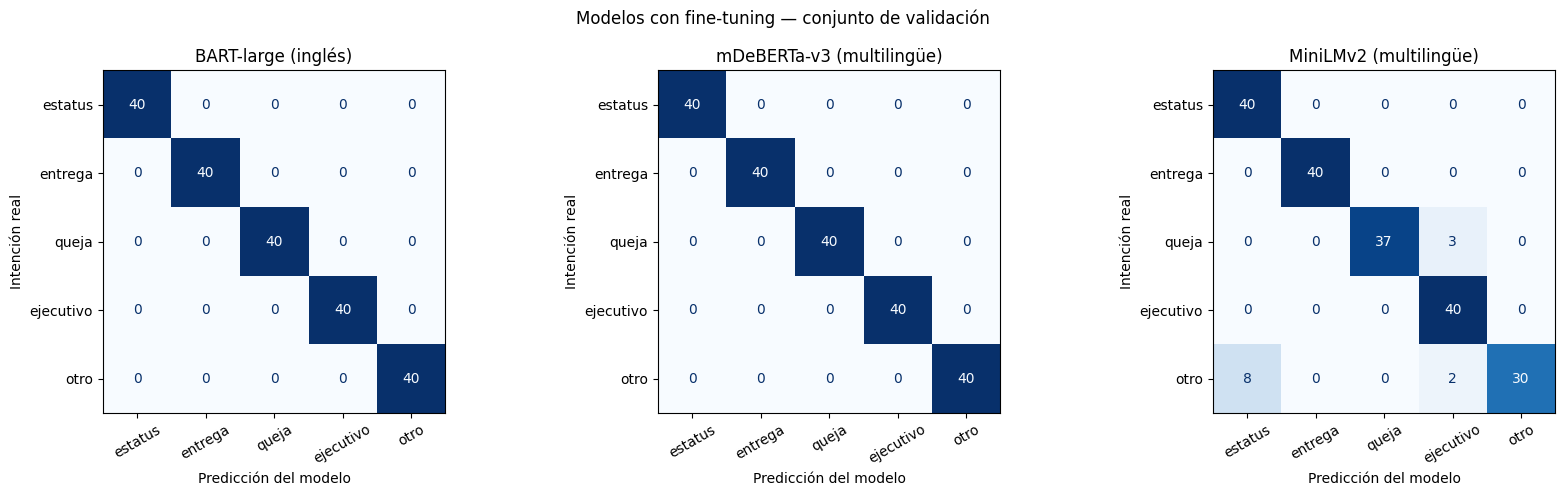

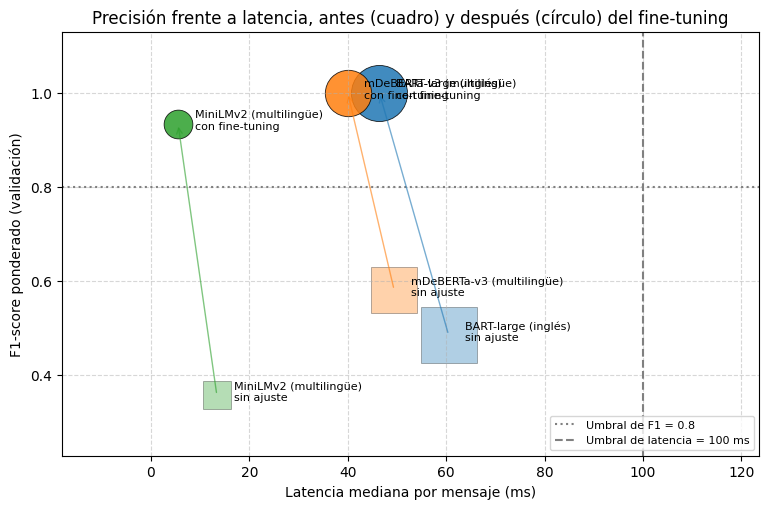

In [19]:
dibujar_matrices([f"ajustado_{n}" for n in MODELOS], list(MODELOS), reales_val, pred_val,
                 "Modelos con fine-tuning — conjunto de validación",
                 "results/matrices_confusion_ajustados_validacion.png")

colores = dict(zip(MODELOS, ["tab:blue", "tab:orange", "tab:green"]))
fig, eje = plt.subplots(figsize=(9, 5.5))
for _, fila in tabla.iterrows():
    ajustado = fila["etapa"] == "con fine-tuning"
    eje.scatter(fila["latencia_mediana_ms"], fila["f1"], s=fila["parametros_millones"] * 4,
                color=colores[fila["modelo"]], alpha=0.85 if ajustado else 0.35,
                marker="o" if ajustado else "s", edgecolor="black", linewidth=0.6)
    eje.annotate(f"{fila['modelo']}\n{fila['etapa']}", (fila["latencia_mediana_ms"], fila["f1"]),
                 textcoords="offset points", xytext=(12, -4), fontsize=8)
for nombre in MODELOS:
    antes = tabla[(tabla["modelo"] == nombre) & (tabla["etapa"] == "sin ajuste")].iloc[0]
    despues = tabla[(tabla["modelo"] == nombre) & (tabla["etapa"] == "con fine-tuning")].iloc[0]
    eje.annotate("", xy=(despues["latencia_mediana_ms"], despues["f1"]),
                 xytext=(antes["latencia_mediana_ms"], antes["f1"]),
                 arrowprops=dict(arrowstyle="->", color=colores[nombre], alpha=0.6))
eje.axhline(UMBRAL_F1, color="gray", linestyle=":", label=f"Umbral de F1 = {UMBRAL_F1}")
eje.axvline(UMBRAL_LATENCIA_MS, color="gray", linestyle="--", label=f"Umbral de latencia = {UMBRAL_LATENCIA_MS} ms")
eje.set_xlabel("Latencia mediana por mensaje (ms)")
eje.set_ylabel("F1-score ponderado (validación)")
eje.set_title("Precisión frente a latencia, antes (cuadro) y después (círculo) del fine-tuning")
eje.margins(x=0.25, y=0.2)
eje.grid(linestyle="--", alpha=0.5)
eje.legend(loc="lower right", fontsize=8)
plt.savefig("results/precision_vs_latencia.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusión parcial.** Después del ajuste los tres modelos cumplen los dos umbrales, así que la elección depende del balance entre precisión y eficiencia. **MiniLMv2** es por mucho el más eficiente (5.5 ms de mediana, 433 MB de memoria de GPU y 1,280 mensajes por segundo), pero se queda en 0.935 de *accuracy* y sus errores pesan: clasifica 8 de 40 mensajes de la clase `otro` como estatus de orden, es decir, los respondería en automático. **BART-large** y **mDeBERTa-v3** empatan en 1.000; mDeBERTa-v3 lo logra con 32 % menos parámetros (279 contra 407 millones) y menos memoria (1,175 contra 1,589 MB), y además es multilingüe. Su latencia es parecida (40.0 y 46.4 ms de mediana) y esa diferencia no es concluyente, porque la GPU de Colab es compartida y los tiempos cambian de una corrida a otra; en ambos casos el percentil 95 ronda los 100 ms. El ajuste también hizo más rápidos a los modelos al procesar por lotes (mDeBERTa-v3 pasó de 30 a 302 mensajes por segundo), porque ya no tienen que comparar cada mensaje con las cinco descripciones.

## 13. Selección del modelo y evaluación final en el conjunto de prueba

Regla de selección, aplicada a los modelos ajustados que cumplen los dos umbrales en validación (precisión y latencia):

1. Se toma como referencia el mayor F1.
2. Los modelos cuyo F1 queda a un punto o menos de esa referencia (0.01, que equivale a 2 mensajes de 200) se consideran empatados, porque una diferencia tan pequeña no es concluyente.
3. Entre los empatados se elige **el de menor latencia**, que además suele ser el que menos recursos ocupa.

Si ningún modelo cumple los umbrales, se elige el de mayor F1.

El conjunto de prueba se usa solo en este punto: se compara el modelo seleccionado **antes** y **después** del ajuste con mensajes que no participaron ni en el entrenamiento ni en la selección.

In [20]:
TOLERANCIA_F1 = 0.01      # diferencia de F1 que se considera empate

candidatos = tabla_ajustados[tabla_ajustados["cumple_todo"]]
if candidatos.empty:
    print("Ningún modelo ajustado cumple los dos umbrales: se elige el de mayor F1.")
    seleccionado = tabla_ajustados.sort_values(["f1", "latencia_mediana_ms"], ascending=[False, True]).iloc[0]
else:
    mejor_f1 = candidatos["f1"].max()
    empatados = candidatos[candidatos["f1"] >= mejor_f1 - TOLERANCIA_F1]
    print(f"Modelos que cumplen los umbrales: {candidatos['modelo'].tolist()}")
    print(f"Empatados con el mejor F1 ({mejor_f1:.4f}): {empatados['modelo'].tolist()}")
    seleccionado = empatados.sort_values(["latencia_mediana_ms", "f1"], ascending=[True, False]).iloc[0]

NOMBRE_SELECCIONADO = seleccionado["modelo"]
MODEL_NAME = seleccionado["id_modelo"]

print("=" * 60)
print("MODELO SELECCIONADO")
print("=" * 60)
print(f"{NOMBRE_SELECCIONADO} ({MODEL_NAME})")
print(f"Validación con fine-tuning: accuracy={seleccionado['accuracy']:.4f}  f1={seleccionado['f1']:.4f}  "
      f"latencia mediana={seleccionado['latencia_mediana_ms']:.1f} ms")

Modelos que cumplen los umbrales: ['BART-large (inglés)', 'mDeBERTa-v3 (multilingüe)', 'MiniLMv2 (multilingüe)']
Empatados con el mejor F1 (1.0000): ['BART-large (inglés)', 'mDeBERTa-v3 (multilingüe)']
MODELO SELECCIONADO
mDeBERTa-v3 (multilingüe) (MoritzLaurer/mDeBERTa-v3-base-mnli-xnli)
Validación con fine-tuning: accuracy=1.0000  f1=1.0000  latencia mediana=40.0 ms


In [21]:
resultado_base, pred_base, conf_base = evaluar_modelo(
    NOMBRE_SELECCIONADO, MODEL_NAME, "sin ajuste", textos_test, reales_test, DISPOSITIVO
)
resultado_ajustado, pred_ajustado, conf_ajustado = evaluar_modelo(
    NOMBRE_SELECCIONADO, rutas_ajustados[NOMBRE_SELECCIONADO], "con fine-tuning",
    textos_test, reales_test, DISPOSITIVO, id_modelo=MODEL_NAME
)

comparacion = aplicar_umbrales(pd.DataFrame([resultado_base, resultado_ajustado]))
comparacion.to_csv("results/comparacion_test.csv", index=False)

print("=" * 60)
print(f"RESULTADOS FINALES — TEST ({len(df_test)} mensajes)")
print("=" * 60)
display(comparacion[["modelo", "etapa", "accuracy", "precision", "recall", "f1", "f1_macro",
                     "latencia_mediana_ms", "latencia_p95_ms",
                     "cumple_precision", "cumple_latencia"]].round(4))

RESULTADOS FINALES — TEST (200 mensajes)


,modelo,etapa,accuracy,precision,recall,f1,f1_macro,latencia_mediana_ms,latencia_p95_ms,cumple_precision,cumple_latencia
0,mDeBERTa-v3 (multilingüe),sin ajuste,0.6,0.6895,0.6,0.5624,0.5624,27.4846,43.0615,False,True
1,mDeBERTa-v3 (multilingüe),con fine-tuning,1.0,1.0000,1.0,1.0000,1.0000,28.7172,73.5519,True,True


CLASSIFICATION REPORT — TEST — sin ajuste
                     precision    recall  f1-score   support

      estatus_orden     0.4368    0.9500    0.5984        40
      fecha_entrega     0.8889    0.2000    0.3265        40
              queja     0.7018    1.0000    0.8247        40
contactar_ejecutivo     0.9200    0.5750    0.7077        40
               otro     0.5000    0.2750    0.3548        40

           accuracy                         0.6000       200
          macro avg     0.6895    0.6000    0.5624       200
       weighted avg     0.6895    0.6000    0.5624       200

CLASSIFICATION REPORT — TEST — con fine-tuning
                     precision    recall  f1-score   support

      estatus_orden     1.0000    1.0000    1.0000        40
      fecha_entrega     1.0000    1.0000    1.0000        40
              queja     1.0000    1.0000    1.0000        40
contactar_ejecutivo     1.0000    1.0000    1.0000        40
               otro     1.0000    1.0000    1.0000   

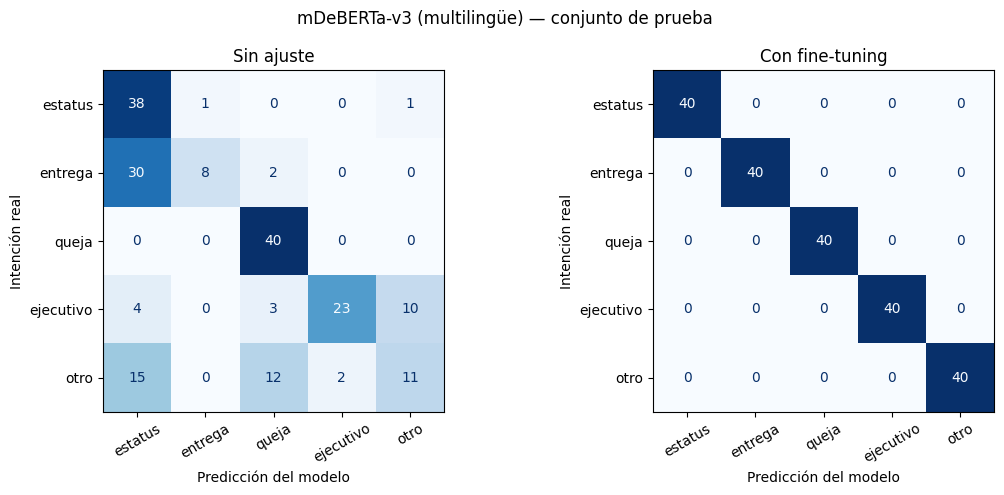

In [22]:
print("=" * 66)
print("CLASSIFICATION REPORT — TEST — sin ajuste")
print("=" * 66)
print(classification_report(reales_test, pred_base, labels=CLASES, digits=4, zero_division=0))
print("=" * 66)
print("CLASSIFICATION REPORT — TEST — con fine-tuning")
print("=" * 66)
print(classification_report(reales_test, pred_ajustado, labels=CLASES, digits=4, zero_division=0))

por_clase += metricas_por_clase(NOMBRE_SELECCIONADO, "sin ajuste", "prueba", reales_test, pred_base)
por_clase += metricas_por_clase(NOMBRE_SELECCIONADO, "con fine-tuning", "prueba", reales_test, pred_ajustado)
pd.DataFrame(por_clase).to_csv("results/metricas_por_clase.csv", index=False)

pred_test = df_test[["id", "mensaje", "intencion"]].copy()
pred_test["pred_sin_ajuste"] = pred_base
pred_test["confianza_sin_ajuste"] = np.round(conf_base, 4)
pred_test["pred_con_fine_tuning"] = pred_ajustado
pred_test["confianza_con_fine_tuning"] = np.round(conf_ajustado, 4)
pred_test.to_csv("results/predicciones_test.csv", index=False)

dibujar_matrices(["pred_sin_ajuste", "pred_con_fine_tuning"], ["Sin ajuste", "Con fine-tuning"],
                 reales_test, pred_test, f"{NOMBRE_SELECCIONADO} — conjunto de prueba",
                 "results/matrices_confusion_test.png")

Por último, se guardan las condiciones de ejecución (GPU, versiones y parámetros del entrenamiento) para que el experimento se pueda repetir en las mismas condiciones.

In [23]:
import json, datetime

entorno = {
    "fecha_ejecucion_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"),
    "gpu": NOMBRE_GPU,
    "dataset": "bitext/Bitext-customer-support-llm-chatbot-training-dataset",
    "mensajes": {"total": len(df), "train": len(df_train), "validation": len(df_val), "test": len(df_test)},
    "tamano_lote_inferencia": TAMANO_LOTE,
    "mensajes_para_latencia": N_LATENCIA,
    "repeticiones_latencia": N_REPETICIONES,
    "fine_tuning": {"learning_rate": 2e-5, "batch_size": 8, "epocas": 3, "weight_decay": 0.01, "semilla": 42,
                    "tiempo_entrenamiento_s": {n: round(t, 1) for n, t in tiempos_entrenamiento.items()}},
    "modelo_seleccionado": MODEL_NAME,
    "versiones": VERSIONES,
}
with open("results/entorno_ejecucion.json", "w", encoding="utf-8") as f:
    json.dump(entorno, f, ensure_ascii=False, indent=2)

print(json.dumps(entorno, ensure_ascii=False, indent=2))

{
  "fecha_ejecucion_utc": "2026-10-11 05:53",
  "gpu": "Tesla T4",
  "dataset": "bitext/Bitext-customer-support-llm-chatbot-training-dataset",
  "mensajes": {
    "total": 2000,
    "train": 1600,
    "validation": 200,
    "test": 200
  },
  "tamano_lote_inferencia": 16,
  "mensajes_para_latencia": 100,
  "repeticiones_latencia": 3,
  "fine_tuning": {
    "learning_rate": 2e-05,
    "batch_size": 8,
    "epocas": 3,
    "weight_decay": 0.01,
    "semilla": 42,
    "tiempo_entrenamiento_s": {
      "BART-large (inglés)": 293.0,
      "mDeBERTa-v3 (multilingüe)": 223.4,
      "MiniLMv2 (multilingüe)": 87.3
    }
  },
  "modelo_seleccionado": "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
  "versiones": {
    "python": "3.13.15",
    "torch": "2.11.0+cu130",
    "transformers": "5.18.0",
    "datasets": "4.8.5",
    "evaluate": "0.4.6",
    "accelerate": "1.15.0",
    "huggingface_hub": "1.33.0",
    "sentencepiece": "0.2.2",
    "scikit-learn": "1.6.1",
    "pandas": "2.2.3",
    "numpy": 

## 14. Conclusiones

1. **Sin ajuste, ningún modelo sirve para el chatbot.** El mejor resultado en validación fue 0.610 de *accuracy*, frente al 0.80 requerido. Los modelos zero-shot confunden la pregunta por la fecha de entrega con la de estatus y no reconocen los temas fuera de alcance.
2. **El fine-tuning resolvió el problema.** Con 1,600 mensajes de ejemplo y menos de cinco minutos de entrenamiento por modelo, los tres superan el umbral: 1.000, 1.000 y 0.935 de *accuracy* en validación.
3. **Modelo recomendado: mDeBERTa-v3** (`MoritzLaurer/mDeBERTa-v3-base-mnli-xnli`) con fine-tuning. Empata en precisión con BART-large usando menos parámetros y menos memoria, y es multilingüe, lo que permitirá atender también los mensajes en español.
4. **Resultado en el conjunto de prueba.** Con mensajes que no participaron en el entrenamiento ni en la selección, el modelo pasó de 0.600 de *accuracy* sin ajuste a 1.000 con fine-tuning, con una latencia mediana de 28.7 ms.
5. **El modelo más rápido no fue la mejor opción.** MiniLMv2 responde en 5.5 ms, pero la latencia no es la limitante del caso (el límite es de 100 ms) y sus errores enviarían a respuesta automática mensajes que requieren a un ejecutivo.

**Limitaciones.** El dataset es público y fue construido a partir de plantillas, por lo que los mensajes de entrenamiento y de prueba se parecen entre sí y el 1.000 obtenido seguramente es más alto que lo que se verá con mensajes reales de los clientes de CAB. Los mensajes están en inglés; el desempeño en español no se midió. La latencia se midió en una GPU compartida y varía entre corridas. El modelo ajustado no se publicó en el Hub: se obtiene de nuevo al ejecutar el cuaderno.